# 📑 Thống Kế & Trực Quan Hóa Dữ Liệu Segmentation (YOLOv8s + Meta SAM ViT-B)

Notebook này tổng hợp toàn bộ thông tin thống kê, vị trí lưu trữ và trực quan hóa dữ liệu nhãn phân vùng **Polygon Segmentation** và **Binary Mask** được sinh tự động từ sự kết hợp giữa **YOLOv8s** và **Meta SAM (Segment Anything Model - ViT-B)** cho bài toán **Phát Hiện Lửa & Khói Sớm (NCKH)**.

In [3]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

# Cấu hình style đồ thị
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["figure.dpi"] = 120

## 📁 1. Vị Trí Lưu Trữ Dữ Liệu Phân Vùng Trong Dự Án

In [4]:
ROOT_DIR = Path("..").resolve() if Path("..").joinpath("Dataset_Segmentation_AutoConverted").exists() else Path(".").resolve()

# 1. Tập dữ liệu ảnh tĩnh (Single Images)
DS1_DIR = ROOT_DIR / "Dataset_Segmentation_AutoConverted"
DS1_IMG = DS1_DIR / "images"
DS1_LBL = DS1_DIR / "labels"

# 2. Tập dữ liệu khung hình video (Video Frames Pipeline)
DS2_DIR = ROOT_DIR / "Dataset_Part2_YOLO_SAM_Segmented"
DS2_LBL = DS2_DIR / "labels"
DS2_MASK = DS2_DIR / "masks"

# 3. Thư mục preview trực quan
PREVIEW_DIR = ROOT_DIR / "sample_previews_1500"

print(f"📌 Thư mục Bộ Dữ Liệu 1 (Ảnh Tĩnh SAM): {DS1_DIR}")
print(f" ├── 🖼️ Ảnh gốc chuẩn hóa:             {DS1_IMG}")
print(f" └── 🏷️ Nhãn Polygon YOLO (.txt):      {DS1_LBL}")
print(f"📌 Thư mục Bộ Dữ Liệu 2 (Video Frames YOLO+SAM): {DS2_DIR}")
print(f" ├── 🏷️ Nhãn Polygon YOLO (.txt):      {DS2_LBL}")
print(f" └── 🎭 Mặt nạ Binary Mask (.png):      {DS2_MASK}")
print(f"📌 Thư mục Previews Trực Quan:        {PREVIEW_DIR}")

📌 Thư mục Bộ Dữ Liệu 1 (Ảnh Tĩnh SAM): E:\NCKH\Code\Fire_Smoke_Early-Detection\Dataset_Segmentation_AutoConverted
 ├── 🖼️ Ảnh gốc chuẩn hóa:             E:\NCKH\Code\Fire_Smoke_Early-Detection\Dataset_Segmentation_AutoConverted\images
 └── 🏷️ Nhãn Polygon YOLO (.txt):      E:\NCKH\Code\Fire_Smoke_Early-Detection\Dataset_Segmentation_AutoConverted\labels
📌 Thư mục Bộ Dữ Liệu 2 (Video Frames YOLO+SAM): E:\NCKH\Code\Fire_Smoke_Early-Detection\Dataset_Part2_YOLO_SAM_Segmented
 ├── 🏷️ Nhãn Polygon YOLO (.txt):      E:\NCKH\Code\Fire_Smoke_Early-Detection\Dataset_Part2_YOLO_SAM_Segmented\labels
 └── 🎭 Mặt nạ Binary Mask (.png):      E:\NCKH\Code\Fire_Smoke_Early-Detection\Dataset_Part2_YOLO_SAM_Segmented\masks
📌 Thư mục Previews Trực Quan:        E:\NCKH\Code\Fire_Smoke_Early-Detection\sample_previews_1500


## 📊 2. Thống Kế Số Lượng & Phân Bổ Nhãn Chi Tiết

In [5]:
def analyze_dataset(lbl_dir):
    if not lbl_dir.exists():
        return 0, 0, 0, 0, []
    
    lbl_files = list(lbl_dir.glob("*.txt"))
    c0, c1 = 0, 0
    imgs_with_obj = 0
    poly_pts = []
    
    for lf in lbl_files:
        with open(lf, "r", encoding="utf-8", errors="ignore") as f:
            lines = f.readlines()
        
        has_obj = False
        for line in lines:
            parts = line.strip().split()
            if len(parts) >= 7:
                has_obj = True
                cls_id = int(parts[0])
                pts = (len(parts) - 1) // 2
                poly_pts.append(pts)
                if cls_id == 0:
                    c0 += 1
                elif cls_id == 1:
                    c1 += 1
        if has_obj:
            imgs_with_obj += 1
            
    return len(lbl_files), imgs_with_obj, c0, c1, poly_pts

n_lbl1, n_obj_img1, c0_1, c1_1, pts1 = analyze_dataset(DS1_LBL)
n_lbl2, n_obj_img2, c0_2, c1_2, pts2 = analyze_dataset(DS2_LBL)

tot_fire = c0_1 + c0_2
tot_smoke = c1_1 + c1_2
tot_polys = tot_fire + tot_smoke
all_pts = pts1 + pts2
avg_pts = np.mean(all_pts) if all_pts else 0

summary_table = pd.DataFrame({
    "Tập Dữ Liệu": ["Bộ 1: Ảnh Tĩnh SAM (Single Images)", "Bộ 2: Video Frames Pipeline (YOLO+SAM)", "🔥 TỔNG CỘNG TOÀN BỘ"],
    "Số tệp nhãn (.txt)": [f"{n_lbl1:,}", f"{n_lbl2:,}", f"{n_lbl1 + n_lbl2:,}"],
    "Số ảnh có đối tượng": [f"{n_obj_img1:,}", f"{n_obj_img2:,}", f"{n_obj_img1 + n_obj_img2:,}"],
    "🔥 Fire (Class 0)": [f"{c0_1:,}", f"{c0_2:,}", f"{tot_fire:,}"],
    "💨 Smoke (Class 1)": [f"{c1_1:,}", f"{c1_2:,}", f"{tot_smoke:,}"],
    "Tổng Polygon Objects": [f"{c0_1 + c1_1:,}", f"{c0_2 + c1_2:,}", f"{tot_polys:,}"],
    "Trung bình điểm/Polygon": [f"{np.mean(pts1):.1f}", f"{np.mean(pts2) if pts2 else 0:.1f}", f"{avg_pts:.1f}"]
})

display(summary_table)

,Tập Dữ Liệu,Số tệp nhãn (.txt),Số ảnh có đối tượng,🔥 Fire (Class 0),💨 Smoke (Class 1),Tổng Polygon Objects,Trung bình điểm/Polygon
0,Bộ 1: Ảnh Tĩnh SAM (Single Images),"10,080","7,385","5,863","5,312","11,175",125.4
1,Bộ 2: Video Frames Pipeline (YOLO+SAM),925,316,123,499,622,168.2
2,🔥 TỔNG CỘNG TOÀN BỘ,"11,005","7,701","5,986","5,811","11,797",127.7


## 📈 3. Biểu Đồ Trực Quan Hóa Phân Bổ Tỷ Lệ & Độ Phức Tạp Nhãn

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_14180\3506926800.py:28: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_14180\3506926800.py:28: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_14180\3506926800.py:28: UserWarning: Glyph 128207 (\N{STRAIGHT RULER}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\LENOVO\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\LENOVO\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\LENOVO\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Gly

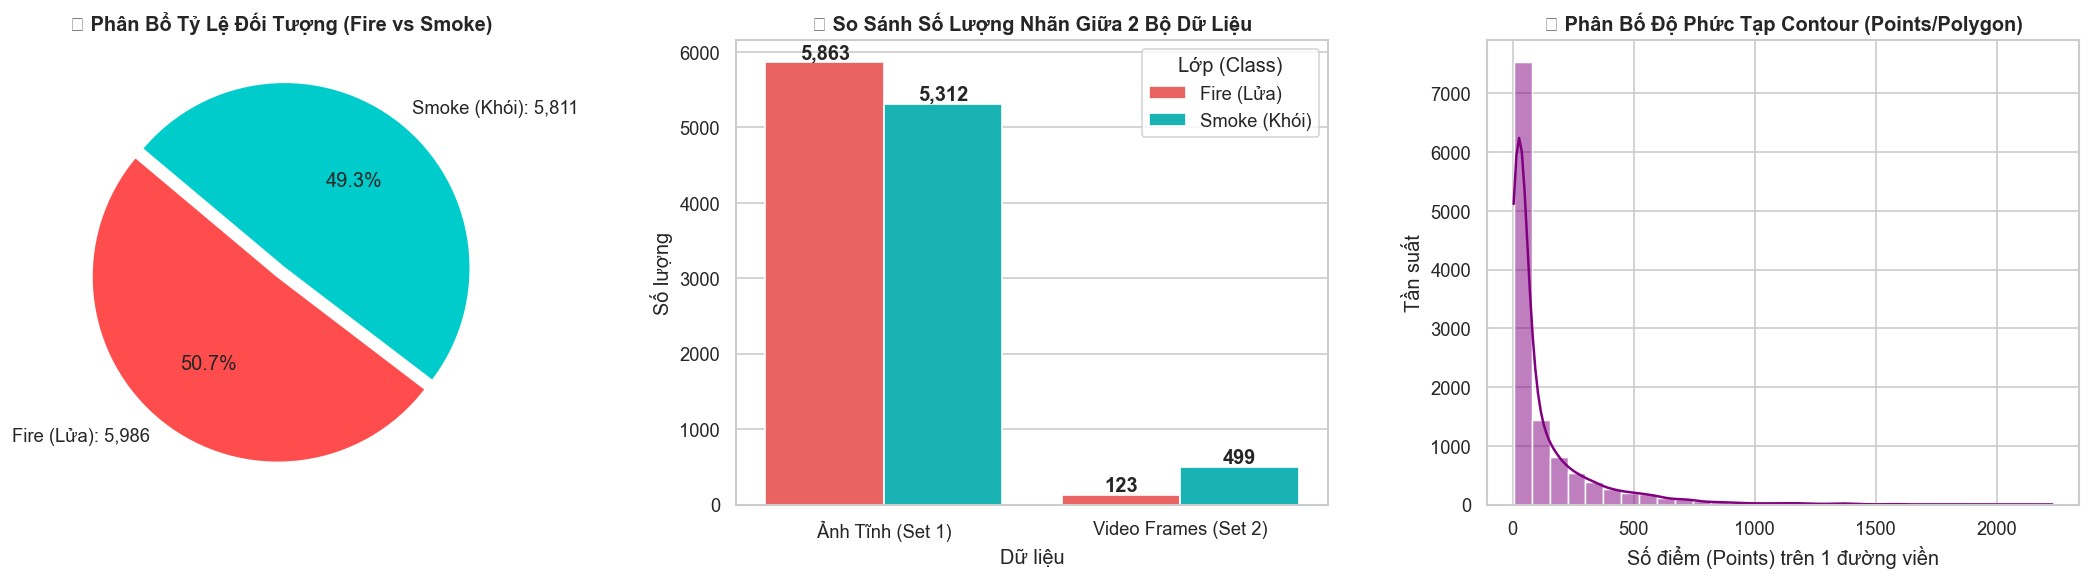

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Biểu đồ tròn tỷ lệ Lửa vs Khói
colors = ["#ff4d4d", "#00cccc"]
axes[0].pie([tot_fire, tot_smoke], labels=[f"Fire (Lửa): {tot_fire:,}", f"Smoke (Khói): {tot_smoke:,}"], 
           autopct="%1.1f%%", startangle=140, colors=colors, explode=(0.03, 0.03))
axes[0].set_title("🔥 Phân Bổ Tỷ Lệ Đối Tượng (Fire vs Smoke)", fontsize=12, fontweight="bold")

# 2. Biểu đồ cột so sánh số lượng giữa 2 bộ dữ liệu
df_bar = pd.DataFrame({
    "Dữ liệu": ["Ảnh Tĩnh (Set 1)", "Ảnh Tĩnh (Set 1)", "Video Frames (Set 2)", "Video Frames (Set 2)"],
    "Lớp (Class)": ["Fire (Lửa)", "Smoke (Khói)", "Fire (Lửa)", "Smoke (Khói)"],
    "Số lượng": [c0_1, c1_1, c0_2, c1_2]
})
sns.barplot(data=df_bar, x="Dữ liệu", y="Số lượng", hue="Lớp (Class)", palette=colors, ax=axes[1])
axes[1].set_title("📊 So Sánh Số Lượng Nhãn Giữa 2 Bộ Dữ Liệu", fontsize=12, fontweight="bold")
for p in axes[1].patches:
    h = p.get_height()
    if h > 0:
        axes[1].annotate(f"{int(h):,}", (p.get_x() + p.get_width() / 2., h + 50), ha='center', fontweight='bold')

# 3. Phân bố số điểm trên đường viền Polygon (Contour Complexity)
sns.histplot(all_pts, bins=30, kde=True, color="purple", ax=axes[2])
axes[2].set_title("📏 Phân Bố Độ Phức Tạp Contour (Points/Polygon)", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Số điểm (Points) trên 1 đường viền")
axes[2].set_ylabel("Tần suất")

plt.tight_layout()
plt.show()

## 🎨 4. Trực Quan Hóa Mẫu Render Overlay (Ảnh Gốc vs Polygon Overlay vs Binary Mask)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_14180\2697108509.py:62: UserWarning: Glyph 128444 (\N{FRAME WITH PICTURE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_14180\2697108509.py:62: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_14180\2697108509.py:62: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_14180\2697108509.py:62: UserWarning: Glyph 127917 (\N{PERFORMING ARTS}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\LENOVO\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128444 (\N{FRAME WITH PICTURE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\LENOVO\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65039 (\N

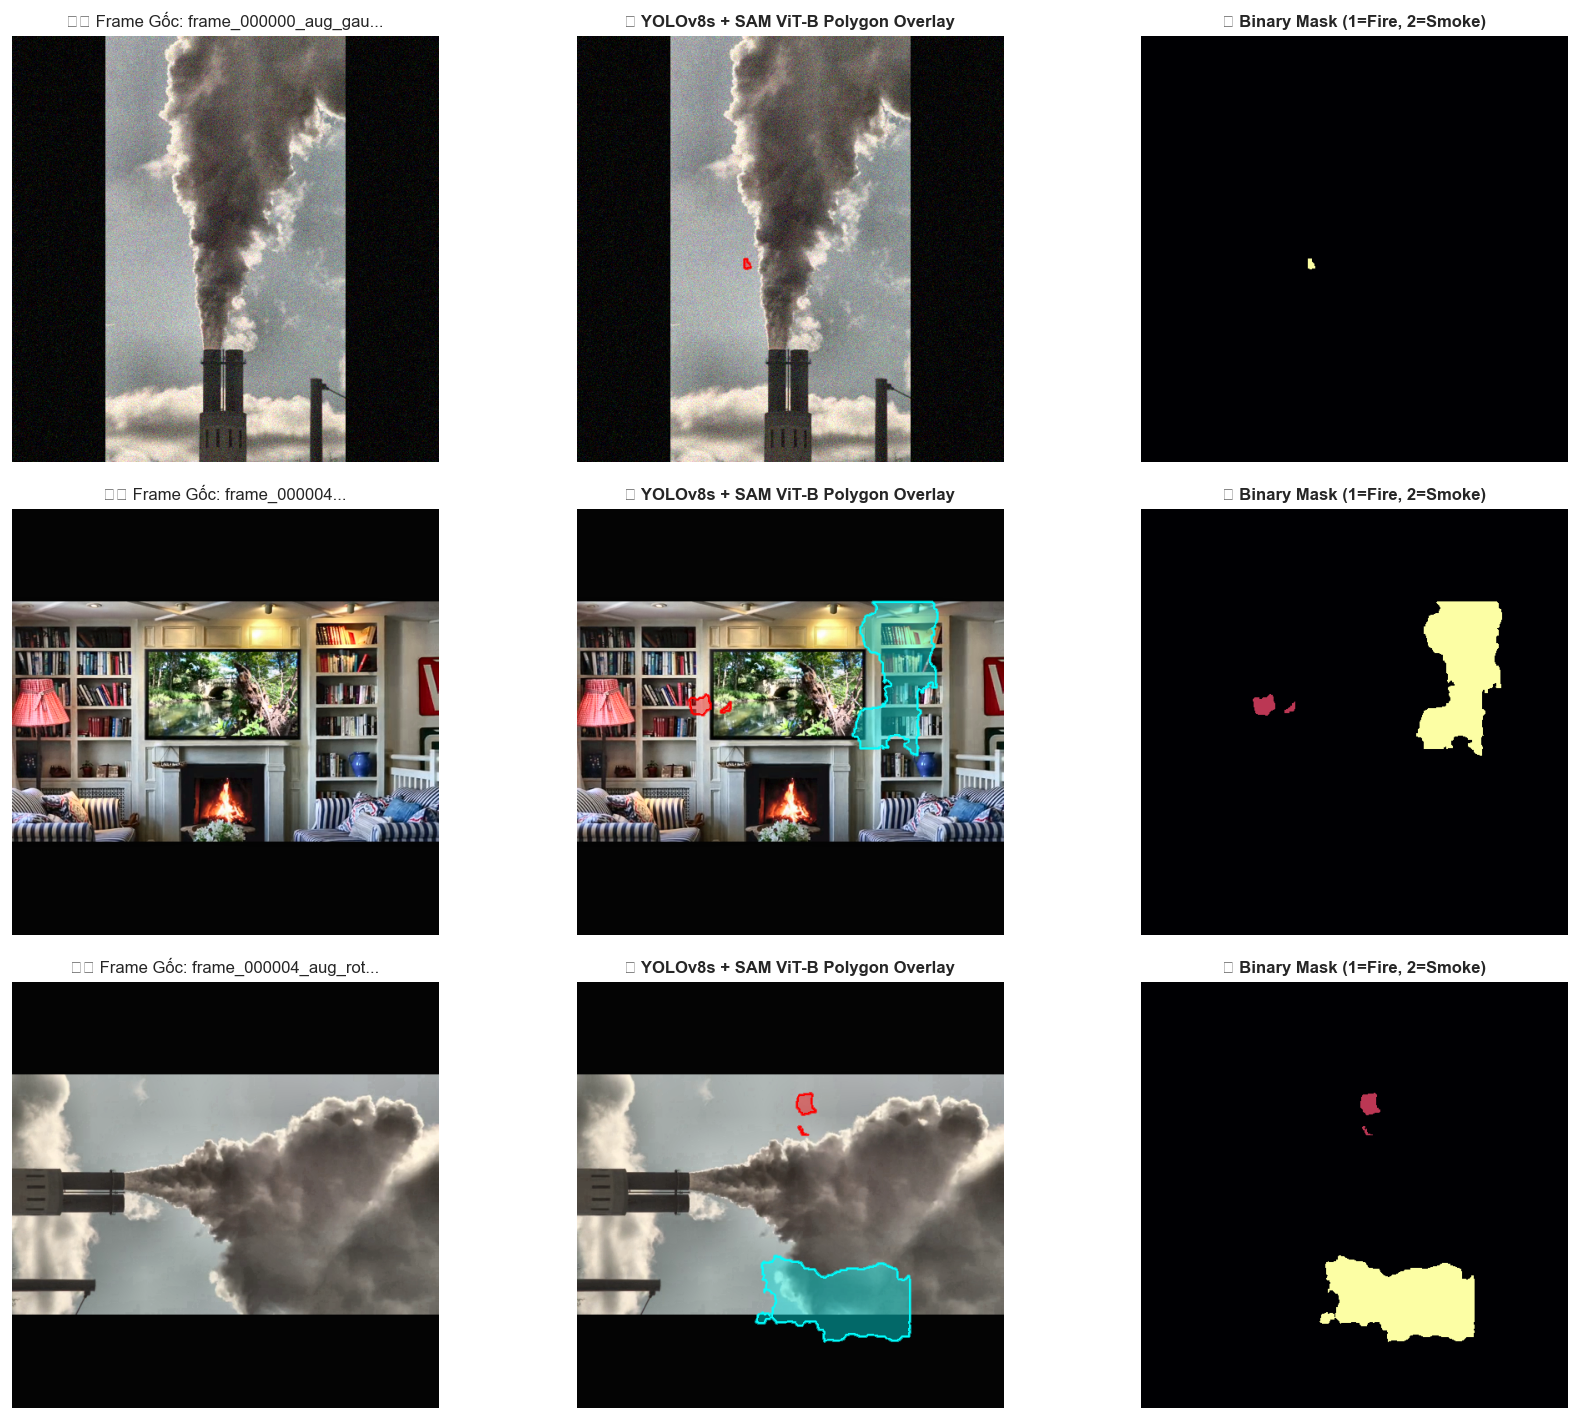

In [7]:
def draw_polygon_overlay(img_path, txt_path):
    img = cv2.imread(str(img_path))
    if img is None:
        return None, None
    
    img_h, img_w = img.shape[:2]
    overlay = img.copy()
    mask_gen = np.zeros((img_h, img_w), dtype=np.uint8)
    
    if txt_path.exists():
        with open(txt_path, "r", encoding="utf-8") as f:
            lines = f.readlines()
            
        for line in lines:
            parts = line.strip().split()
            if len(parts) >= 7:
                cls_id = int(parts[0])
                coords = np.array(parts[1:], dtype=np.float32).reshape(-1, 2)
                pts = np.int32(coords * [img_w, img_h])
                
                color = (0, 0, 255) if cls_id == 0 else (255, 255, 0) # Red for Fire, Cyan for Smoke
                mask_val = 1 if cls_id == 0 else 2
                
                cv2.fillPoly(overlay, [pts], color)
                cv2.fillPoly(mask_gen, [pts], mask_val)
                cv2.polylines(img, [pts], True, color, 2)
                
    result = cv2.addWeighted(overlay, 0.4, img, 0.6, 0)
    return cv2.cvtColor(result, cv2.COLOR_BGR2RGB), mask_gen

# Hiển thị 3 mẫu từ tập Video Frames Pipeline
sample_files = [f for f in DS2_LBL.glob("*.txt") if f.stat().st_size > 50][:3]
v_frames_dir = ROOT_DIR / "Dataset_Part2_Video_Frames"

if sample_files:
    fig, axes = plt.subplots(len(sample_files), 3, figsize=(15, 4 * len(sample_files)))
    if len(sample_files) == 1:
        axes = [axes]
        
    for idx, txt_p in enumerate(sample_files):
        stem = txt_p.stem
        # Tìm ảnh gốc tương ứng
        img_matches = list(v_frames_dir.rglob(f"{stem}.png")) + list(v_frames_dir.rglob(f"{stem}.jpg"))
        
        if img_matches:
            img_p = img_matches[0]
            raw_img = cv2.cvtColor(cv2.imread(str(img_p)), cv2.COLOR_BGR2RGB)
            overlay_img, gen_mask = draw_polygon_overlay(img_p, txt_p)
            
            axes[idx][0].imshow(raw_img)
            axes[idx][0].set_title(f"🖼️ Frame Gốc: {stem[:20]}...", fontsize=10)
            axes[idx][0].axis("off")
            
            axes[idx][1].imshow(overlay_img)
            axes[idx][1].set_title("🔥 YOLOv8s + SAM ViT-B Polygon Overlay", fontsize=10, fontweight="bold")
            axes[idx][1].axis("off")
            
            axes[idx][2].imshow(gen_mask, cmap="inferno")
            axes[idx][2].set_title("🎭 Binary Mask (1=Fire, 2=Smoke)", fontsize=10, fontweight="bold")
            axes[idx][2].axis("off")
            
    plt.tight_layout()
    plt.show()

## 🖼️ 5. Trực Quan Hóa Mẫu Render Trực Tiếp Từ Cloud GPU Previews

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_14180\1321046161.py:14: UserWarning: Glyph 128444 (\N{FRAME WITH PICTURE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_14180\1321046161.py:14: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  plt.tight_layout()


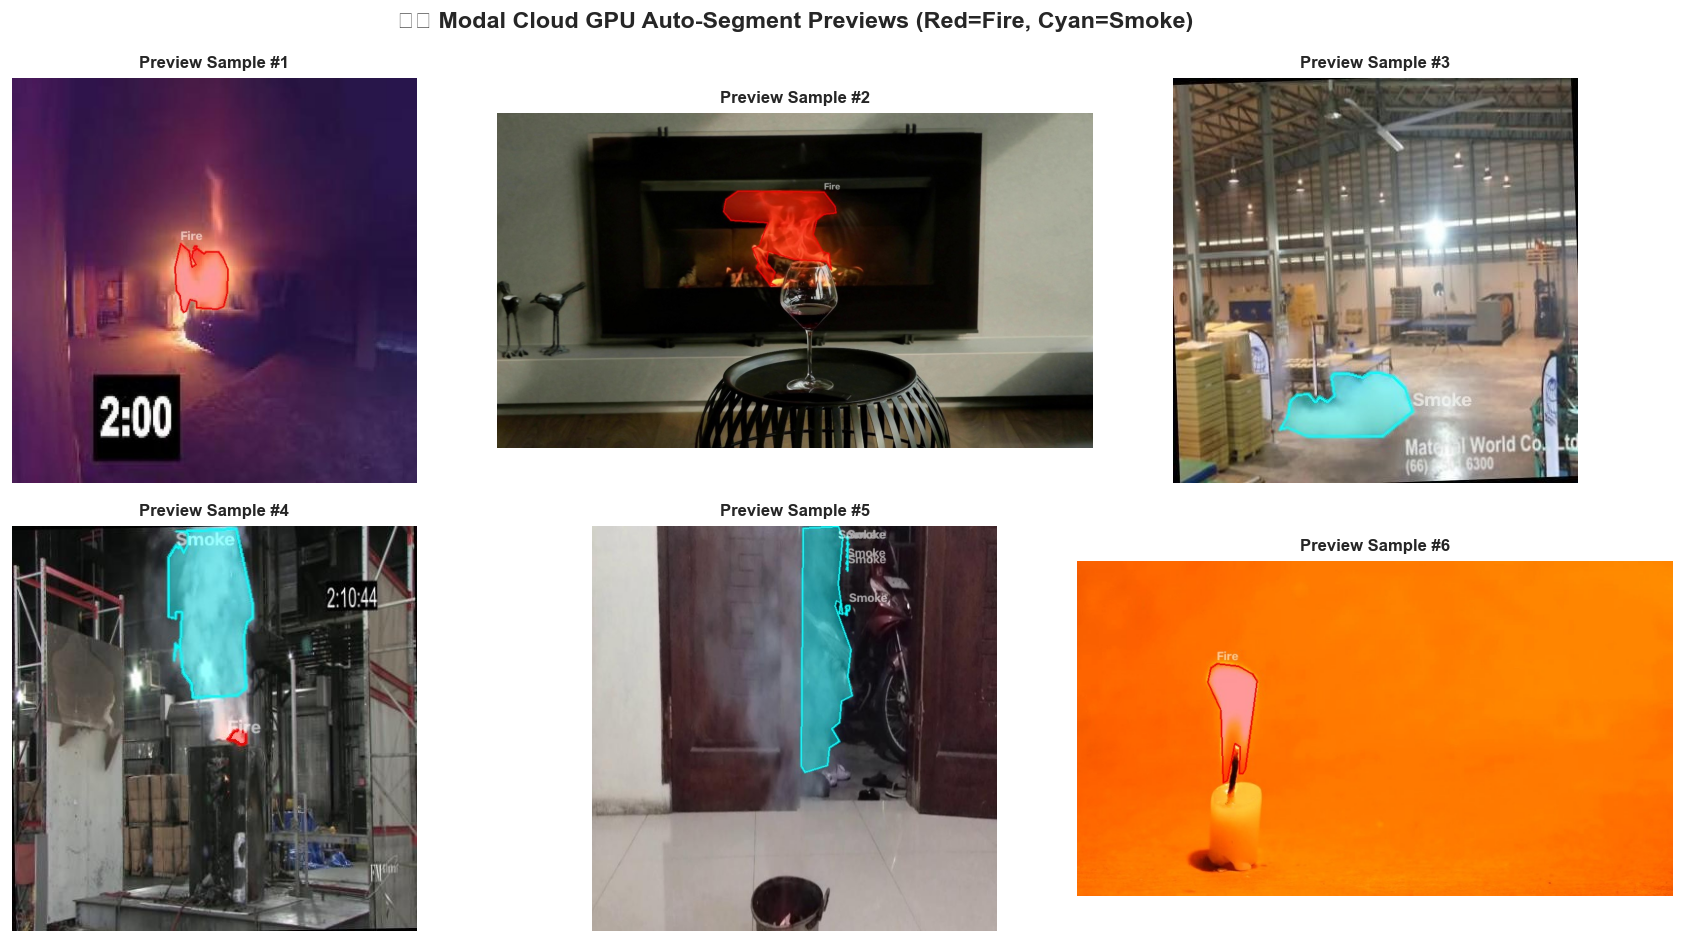

In [8]:
vis_previews = list(PREVIEW_DIR.glob("*.jpg"))[:6]

if vis_previews:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.flatten()
    
    for idx, vis_p in enumerate(vis_previews):
        img_rgb = cv2.cvtColor(cv2.imread(str(vis_p)), cv2.COLOR_BGR2RGB)
        axes[idx].imshow(img_rgb)
        axes[idx].set_title(f"Preview Sample #{idx+1}", fontsize=10, fontweight="bold")
        axes[idx].axis("off")
        
    plt.suptitle("🖼️ Modal Cloud GPU Auto-Segment Previews (Red=Fire, Cyan=Smoke)", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()